In [ ]:
import pandas as pd 
import numpy as np
import seaborn as sns
import geopandas as gpd
import matplotlib.pyplot as plt
import utils.queries as qs

In [ ]:
df = qs.get_flats_for_sale()
data = gpd.read_file('Data/GeoJsons/krakow-dzielnice.geojson')
data[['2','3']] = data.name.str.split(' ', expand=True)[[2,3]]
data['district'] = ''
for i in range(0,len(data)):
    if data['3'][i] == None:
        data['district'][i] = data['2'][i]
    else:
        data['district'][i] = data['2'][i] + ' ' + data['3'][i]
data.drop(columns=['2','3'], inplace=True)
merge = pd.merge(data,df,on='district',how='right')
merge['one'] = merge['name'].apply(lambda x: 'Unknown' if pd.isna(x) == True else 'Known')
merge['district'] = merge.apply(lambda row: row['district'] if row.one == 'Known' else 'Unknown', axis=1)
merge.drop(columns=['cartodb_id','Unnamed: 0','one'],inplace=True)
merge = merge[merge['sqrmeter']!='Szlak,']
merge['sqrmeter'] = merge['sqrmeter'].astype(float)

/var/folders/x8/q__bzqys7yg57g9twpxbqxqm0000gn/T/ipykernel_7857/897719877.py:7: FutureWarning: ChainedAssignmentError: behaviour will change in pandas 3.0!
You are setting values through chained assignment. Currently this works in certain cases, but when using Copy-on-Write (which will become the default behaviour in pandas 3.0) this will never work to update the original DataFrame or Series, because the intermediate object on which we are setting values will behave as a copy.
A typical example is when you are setting values in a column of a DataFrame, like:

df["col"][row_indexer] = value

Use `df.loc[row_indexer, "col"] = values` instead, to perform the assignment in a single step and ensure this keeps updating the original `df`.

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

  data['district'][i] = data['2'][i]
/var/folders/x8/q__bzqys7yg57g9twpxbqxqm0000gn/T/ipykernel_7857/897719877.py:7: 

In [56]:
new_df = pd.DataFrame()
for i in merge.district.unique():
    df = merge[merge['district'] == i]

    lower = (df['price_per_m2'].mean()) - (df['price_per_m2'].std() * 3)
    upper = (df['price_per_m2'].mean()) + (df['price_per_m2'].std() * 3)

    df = df[df['price_per_m2'].notna()]
    df = df[(df['price_per_m2'] > lower) & (df['price_per_m2'] < upper)]

    new_df = pd.concat([new_df,df])

In [57]:
new_df

,name,geometry,district,title,price,price_per_m2,sqrmeter,rooms,floor,page,street,max_floor
0,Dzielnica IV Prądnik Biały,"MULTIPOLYGON (((19.86434 50.10174, 19.86415 50...",Prądnik Biały,Atrakcyjne mieszkanie w stanie deweloperskim**...,935000.0,13883.0,67.0,3,3.0,0,Zygmunta Glogera,3.0
32,Dzielnica IV Prądnik Biały,"MULTIPOLYGON (((19.86434 50.10174, 19.86415 50...",Prądnik Biały,3-pok. Krowodrza Górka Po remoncie Blisko pętl...,750000.0,16667.0,45.0,3,2.0,0,Opolska,10.0
37,Dzielnica IV Prądnik Biały,"MULTIPOLYGON (((19.86434 50.10174, 19.86415 50...",Prądnik Biały,Kawalerka na sprzedaż,548238.0,16654.0,32.0,1,1.0,1,Bociana,NaN
38,Dzielnica IV Prądnik Biały,"MULTIPOLYGON (((19.86434 50.10174, 19.86415 50...",Prądnik Biały,Mieszkanie na sprzedaż,944612.0,14797.0,63.0,4,1.0,1,Bociana,NaN
44,Dzielnica IV Prądnik Biały,"MULTIPOLYGON (((19.86434 50.10174, 19.86415 50...",Prądnik Biały,## Sprzedam piękne mieszkanie 80m2 | 4 osobne ...,989000.0,12362.0,80.0,4,1.0,1,Bursztynowa,4.0
...,...,...,...,...,...,...,...,...,...,...,...,...
1775,Dzielnica X Swoszowice,"MULTIPOLYGON (((19.8874 49.98039, 19.88749 49....",Swoszowice,super 3 pok. | m. postojowe | 2-stronne mieszk...,665000.0,13580.0,48.0,3,3.0,51,Macieja Dębskiego,3.0
5132,Dzielnica X Swoszowice,"MULTIPOLYGON (((19.8874 49.98039, 19.88749 49....",Swoszowice,Kraków Swoszowice Petrażyckiego ⭐️ 2 pok 50m2 ...,699000.0,13958.0,50.0,2,1.0,149,Leona Petrażyckiego,3.0
5155,Dzielnica X Swoszowice,"MULTIPOLYGON (((19.8874 49.98039, 19.88749 49....",Swoszowice,MIESZKANIE 3 POKOJE/90m2/Swoszowice,689000.0,9569.0,72.0,3,1.0,150,Myślenicka,1.0
5356,Dzielnica X Swoszowice,"MULTIPOLYGON (((19.8874 49.98039, 19.88749 49....",Swoszowice,Swoszowice - 33 m 2 z ogrodkiem,635000.0,19242.0,33.0,2,0.0,155,Tytusa Chałubińskiego,2.0


In [54]:
merge

,name,geometry,district,title,price,price_per_m2,sqrmeter,rooms,floor,page,street,max_floor
0,Dzielnica IV Prądnik Biały,"MULTIPOLYGON (((19.86434 50.10174, 19.86415 50...",Prądnik Biały,Atrakcyjne mieszkanie w stanie deweloperskim**...,935000.0,13883.0,67.0,3,3.0,0,Zygmunta Glogera,3.0
1,Dzielnica XIII Podgórze,"MULTIPOLYGON (((19.92749 50.03022, 19.92786 50...",Podgórze,Mieszkanie na sprzedaż,892788.0,17700.0,50.0,3,2.0,0,Jerozolimska,6.0
2,Dzielnica VII Zwierzyniec,"MULTIPOLYGON (((19.82633 50.0324, 19.82572 50....",Zwierzyniec,NOWY Luksusowy Apartament - gotowy do wejścia ...,2250000.0,19068.0,118.0,4,1.0,0,Zakrzowiecka,2.0
3,Dzielnica XIII Podgórze,"MULTIPOLYGON (((19.92749 50.03022, 19.92786 50...",Podgórze,Mieszkanie na sprzedaż,1470350.0,17500.0,84.0,4,2.0,0,Jerozolimska,6.0
4,Dzielnica I Stare Miasto,"MULTIPOLYGON (((19.92543 50.05927, 19.92547 50...",Stare Miasto,**Atrakcyjne**do Wejścia**Stare Miasto**,1694000.0,22000.0,77.0,2,1.0,0,Tarłowska,5.0
...,...,...,...,...,...,...,...,...,...,...,...,...
6436,Dzielnica VI Bronowice,"MULTIPOLYGON (((19.83455 50.08853, 19.83552 50...",Bronowice,Nowe osiedle mieszkaniowe Bronowice,866772.0,16646.0,52.0,2,2.0,198,Na Błonie,4.0
6437,Dzielnica VI Bronowice,"MULTIPOLYGON (((19.83455 50.08853, 19.83552 50...",Bronowice,Nowe osiedle mieszkaniowe Bronowice,877486.0,16797.0,52.0,2,3.0,198,Na Błonie,4.0
6438,Dzielnica VI Bronowice,"MULTIPOLYGON (((19.83455 50.08853, 19.83552 50...",Bronowice,Nowe osiedle mieszkaniowe Bronowice,885540.0,17066.0,51.0,2,1.0,198,Na Błonie,4.0
6439,Dzielnica VI Bronowice,"MULTIPOLYGON (((19.83455 50.08853, 19.83552 50...",Bronowice,Nowe osiedle mieszkaniowe Bronowice,888591.0,17125.0,51.0,2,0.0,198,Na Błonie,4.0


In [58]:
df_ = new_df.copy()

In [99]:
new_df.count()

name            2862
geometry        2862
district        6232
title           6232
price           6232
price_per_m2    6232
sqrmeter        6232
rooms           6230
floor           6186
page            6232
street          6232
max_floor       5463
dtype: int64

In [102]:
new_df.groupby(by='district')['price'].count()

district
Bieńczyce               76
Bronowice              227
Czyżyny                150
Dębniki                 74
Grzegórzki             181
Krowodrza              332
Mistrzejowice          125
Nowa Huta              110
Podgórze               436
Podgórze Duchackie      66
Prądnik Biały          615
Prądnik Czerwony        92
Stare Miasto           289
Swoszowice              10
Unknown               3370
Zwierzyniec             79
Name: price, dtype: int64

In [104]:
pd.DataFrame(new_df.groupby(by='district')['price_per_m2'].median().round(2)).join(pd.DataFrame(new_df.groupby(by='district')['price_per_m2'].mean().round(2)), lsuffix='_median', rsuffix='_mean').join(pd.DataFrame(new_df.groupby(by='district')['price'].count())).rename(columns={'price_per_m2_median':'Median_price_m2','price_per_m2_mean':'Mean_price_m2','price':'No. of offers'})

,Median_price_m2,Mean_price_m2,No. of offers
district,,,
Bieńczyce,14053.0,14011.76,76
Bronowice,17899.0,17644.16,227
Czyżyny,16781.0,16740.87,150
Dębniki,15680.0,16176.76,74
Grzegórzki,20285.0,20796.14,181
Krowodrza,17797.0,18394.59,332
Mistrzejowice,13547.0,13769.78,125
Nowa Huta,13406.5,13574.41,110
Podgórze,17387.5,16943.28,436


,price_per_m2
district,
Bieńczyce,14011.76
Bronowice,17644.16
Czyżyny,16740.87
Dębniki,16176.76
Grzegórzki,20796.14
Krowodrza,18394.59
Mistrzejowice,13769.78
Nowa Huta,13574.41
Podgórze,16943.28


In [85]:
df_.groupby(by='district')['price_per_m2'].mean().round(2)

district
Bieńczyce             14011.76
Bronowice             17644.16
Czyżyny               16740.87
Dębniki               16176.76
Grzegórzki            20796.14
Krowodrza             18394.59
Mistrzejowice         13769.78
Nowa Huta             13574.41
Podgórze              16943.28
Podgórze Duchackie    15420.45
Prądnik Biały         15137.05
Prądnik Czerwony      15086.90
Stare Miasto          20676.51
Swoszowice            12411.80
Unknown               16141.03
Zwierzyniec           21265.42
Name: price_per_m2, dtype: float64

AttributeError: Rectangle.set() got an unexpected keyword argument 'xlabel'

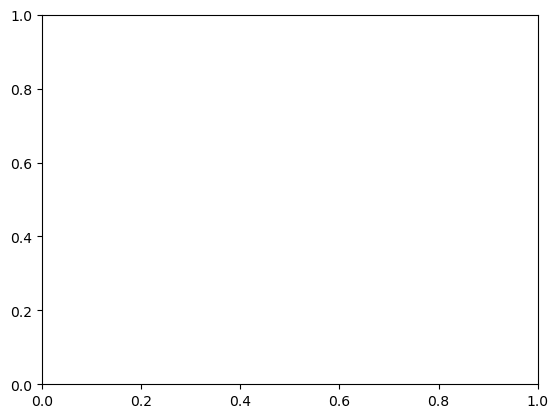

In [84]:
sns.histplot(df_, x='price_per_m2', xlabel='Price per m2')

Text(0.5, 0, 'Price for m2')

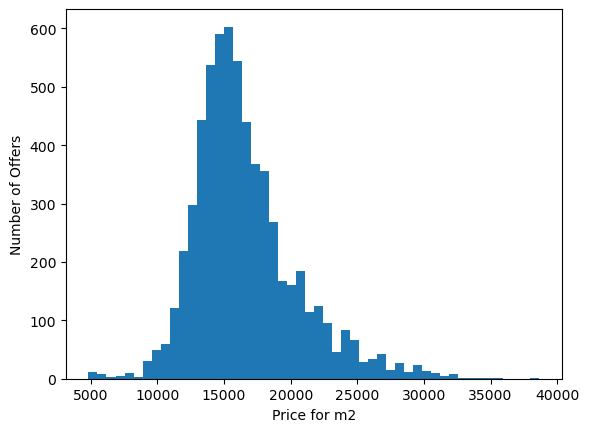

In [83]:
plt.hist(df_['price_per_m2'], density=False, bins=50)  # density=False would make counts
plt.ylabel('Number of Offers')
plt.xlabel('Price for m2')

In [126]:
df_.join(merge[['geometry','district']].set_index('district'))

,Median_price_m2,Mean_price_m2,geometry
district,,,
Bieńczyce,14053.0,14011.76,"MULTIPOLYGON (((20.00353 50.08813, 20.00427 50..."
Bieńczyce,14053.0,14011.76,"MULTIPOLYGON (((20.00353 50.08813, 20.00427 50..."
Bieńczyce,14053.0,14011.76,"MULTIPOLYGON (((20.00353 50.08813, 20.00427 50..."
Bieńczyce,14053.0,14011.76,"MULTIPOLYGON (((20.00353 50.08813, 20.00427 50..."
Bieńczyce,14053.0,14011.76,"MULTIPOLYGON (((20.00353 50.08813, 20.00427 50..."
...,...,...,...
Zwierzyniec,20756.0,21265.42,"MULTIPOLYGON (((19.82633 50.0324, 19.82572 50...."
Zwierzyniec,20756.0,21265.42,"MULTIPOLYGON (((19.82633 50.0324, 19.82572 50...."
Zwierzyniec,20756.0,21265.42,"MULTIPOLYGON (((19.82633 50.0324, 19.82572 50...."


# XTB Excel

In [12]:
import pandas as pd
from datetime import datetime as dt

In [32]:
df_xtb_closed = pd.read_excel('account_52157453_pl_xlsx_2005-12-31_2025-10-08.xlsx', skiprows=11,header=1, index_col=2).iloc[:-1,[1,2,3,4,5,6,7,10,18]].reset_index().set_index('Position')
df_xtb_closed

,Symbol,Type,Volume,Open time,Open price,Close time,Close price,Purchase value,Gross P/L
Position,,,,,,,,,
1944346732,US500,BUY,0.020,2025-07-29 09:14:18.473,6431.70,2025-08-01 15:45:26.038,6267.40,NaN,-606.45
1974374314,US100,SELL,0.005,2025-08-14 16:47:45.114,24000.55,2025-08-25 12:01:50.062,23504.04,NaN,181.06
1952943649,US100,BUY,0.005,2025-08-01 17:52:40.961,22982.24,2025-08-25 12:01:54.922,23502.21,NaN,189.62
1944352898,DE40,BUY,0.002,2025-07-29 09:16:44.788,24196.30,2025-10-02 15:56:34.542,24594.30,NaN,84.68


In [33]:
df_xtb_open = pd.read_excel('account_52157453_pl_xlsx_2005-12-31_2025-10-08.xlsx',sheet_name=1, skiprows=9,header=1, index_col=2).iloc[:-1,[1,2,3,4,5,6,7,14]].reset_index().set_index('Position')

In [36]:
df_xtb_open.head(5)

,Symbol,Type,Volume,Open time,Open price,Market price,Purchase value,Gross P/L
Position,,,,,,,,
1944349765,2B76.DE,BUY,1.0000,2025-07-29 09:15:29.944,13.458,13.992,57.72,1.47
2001655284,IS3S.DE,BUY,0.5114,2025-09-02 11:10:24.608,45.120,47.340,98.98,3.43
2001655347,2B76.DE,BUY,1.0000,2025-09-02 11:10:25.938,12.960,13.992,55.59,3.60
1944349769,IUSN.DE,BUY,3.0000,2025-07-29 09:15:29.963,7.234,7.574,93.08,3.04
1944349708,2B76.DE,BUY,0.7152,2025-07-29 09:15:28.367,13.458,13.992,41.28,1.05


# All Positions - Open and Close

In [34]:
df_all = pd.concat([df_xtb_closed,df_xtb_open])
#len(df_all) == len(df_all.drop_duplicates(subset=['Symbol','Type','Volume','Open time','Open price']))
df_all = df_all.sort_values(by='Open time')

In [35]:
df_all

,Symbol,Type,Volume,Open time,Open price,Close time,Close price,Purchase value,Gross P/L,Market price
Position,,,,,,,,,,
1903740214,2B76.DE,BUY,0.4362,2025-07-02 11:28:43.844,12.780,NaT,NaN,23.83,1.99,13.992
1903740217,XDWH.DE,BUY,0.5741,2025-07-02 11:28:43.855,44.140,NaT,NaN,108.33,6.53,47.295
1903740219,SXRT.DE,BUY,0.3443,2025-07-02 11:28:43.866,201.800,NaT,NaN,297.02,14.07,213.600
1903740221,SXR8.DE,BUY,0.1235,2025-07-02 11:28:43.879,562.520,NaT,NaN,296.98,24.30,614.980
1903740223,IS3N.DE,BUY,0.0722,2025-07-02 11:28:43.889,33.527,NaT,NaN,10.35,1.17,37.726
1903740252,2B76.DE,BUY,5.0000,2025-07-02 11:28:44.821,12.780,NaT,NaN,273.17,22.77,13.992
1903740253,XDWH.DE,BUY,1.0000,2025-07-02 11:28:44.829,44.140,NaT,NaN,188.69,11.37,47.295
1903740255,IS3N.DE,BUY,2.0000,2025-07-02 11:28:44.837,33.527,NaT,NaN,286.65,32.52,37.726
1903742261,2B76.DE,BUY,0.8120,2025-07-02 11:30:33.831,12.780,NaT,NaN,44.36,3.70,13.992


In [5]:
df_example = df_all.iloc[1,:]

In [6]:
df_example

Symbol                               XDWH.DE
Type                                     BUY
Volume                                0.5741
Open time         2025-07-02 11:28:43.855000
Open price                             44.14
Close time                               NaT
Close price                              NaN
Purchase value                        108.33
Gross P/L                               6.53
Name: 1903740217, dtype: object

In [26]:
from datetime import date, timedelta

In [28]:
start_date = df_example['Open time']#.strftime('%Y-%m-%d')
end_date = dt.today()#.strftime('%Y-%m-%d')

delta = end_date - start_date   # returns timedelta

for i in range(delta.days + 1):
    day = start_date + timedelta(days=i)
    df_example['Open time'] = day
    df_example['Open price'] = 0
    pd.concat()

2025-07-02 11:28:43.855000
2025-07-03 11:28:43.855000
2025-07-04 11:28:43.855000
2025-07-05 11:28:43.855000
2025-07-06 11:28:43.855000
2025-07-07 11:28:43.855000
2025-07-08 11:28:43.855000
2025-07-09 11:28:43.855000
2025-07-10 11:28:43.855000
2025-07-11 11:28:43.855000
2025-07-12 11:28:43.855000
2025-07-13 11:28:43.855000
2025-07-14 11:28:43.855000
2025-07-15 11:28:43.855000
2025-07-16 11:28:43.855000
2025-07-17 11:28:43.855000
2025-07-18 11:28:43.855000
2025-07-19 11:28:43.855000
2025-07-20 11:28:43.855000
2025-07-21 11:28:43.855000
2025-07-22 11:28:43.855000
2025-07-23 11:28:43.855000
2025-07-24 11:28:43.855000
2025-07-25 11:28:43.855000
2025-07-26 11:28:43.855000
2025-07-27 11:28:43.855000
2025-07-28 11:28:43.855000
2025-07-29 11:28:43.855000
2025-07-30 11:28:43.855000
2025-07-31 11:28:43.855000
2025-08-01 11:28:43.855000
2025-08-02 11:28:43.855000
2025-08-03 11:28:43.855000
2025-08-04 11:28:43.855000
2025-08-05 11:28:43.855000
2025-08-06 11:28:43.855000
2025-08-07 11:28:43.855000
2

In [22]:
dates_between = []

In [24]:
end_date.day_name()

AttributeError: 'datetime.datetime' object has no attribute 'day_name'

In [15]:
pd.to_datetime(start_date)

AttributeError: 'Timestamp' object has no attribute 'dt'

In [142]:
start_date.dt.day_name()

AttributeError: 'str' object has no attribute 'dt'

In [41]:
800+60+(250*5)+(380*5)+(300*5)+750+640

7590

In [1]:
import yfinance as yf

stock = yf.Ticker("AAPL")

# Stock info
print(stock.info)

# Historical data
print(stock.history(period="1d"))

# News
print(stock.news)

{'address1': 'One Apple Park Way', 'city': 'Cupertino', 'state': 'CA', 'zip': '95014', 'country': 'United States', 'phone': '(408) 996-1010', 'website': 'https://www.apple.com', 'industry': 'Consumer Electronics', 'industryKey': 'consumer-electronics', 'industryDisp': 'Consumer Electronics', 'sector': 'Technology', 'sectorKey': 'technology', 'sectorDisp': 'Technology', 'longBusinessSummary': 'Apple Inc. designs, manufactures, and markets smartphones, personal computers, tablets, wearables, and accessories worldwide. The company offers iPhone, a line of smartphones; Mac, a line of personal computers; iPad, a line of multi-purpose tablets; and wearables, home, and accessories comprising AirPods, Apple Vision Pro, Apple TV, Apple Watch, Beats products, and HomePod, as well as Apple branded and third-party accessories. It also provides AppleCare support and cloud services; and operates various platforms, including the App Store that allow customers to discover and download applications and

In [29]:
stock.news[1]['content'].keys()

dict_keys(['id', 'contentType', 'title', 'description', 'summary', 'pubDate', 'displayTime', 'isHosted', 'bypassModal', 'previewUrl', 'thumbnail', 'provider', 'canonicalUrl', 'clickThroughUrl', 'metadata', 'finance', 'storyline'])

In [30]:
stock.news[1]['content']['title']

'Amazon partners up with Delta to provide high-speed internet'

In [33]:
stock.news[1]['content']['summary']

"Yahoo Finance Tech Editor Dan Howley talks to Market Domination Host Josh Lipton about a recently announced partnership between Delta Air Lines (DAL) and Amazon (AMZN) to use Amazon's Low Earth Orbit (LEO) satellites to provide internet access on flights."

In [36]:
stock.news[1]['content']['pubDate']

'2026-03-31T21:33:46Z'

In [6]:
pip uninstall streamlit

  Using cached blinker-1.9.0-py3-none-any.whl.metadata (1.6 kB)
  Using cached toml-0.10.2-py2.py3-none-any.whl.metadata (7.1 kB)
  Using cached gitdb-4.0.12-py3-none-any.whl.metadata (1.2 kB)
  Using cached jsonschema_specifications-2025.9.1-py3-none-any.whl.metadata (2.9 kB)
  Using cached referencing-0.37.0-py3-none-any.whl.metadata (2.8 kB)
  Using cached h11-0.16.0-py3-none-any.whl.metadata (8.3 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.2/9.2 MB 5.1 MB/s eta 0:00:00a 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 797.0/797.0 kB 5.3 MB/s eta 0:00:00
Using cached blinker-1.9.0-py3-none-any.whl (8.5 kB)
Using cached gitdb-4.0.12-py3-none-any.whl (62 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.3/11.3 MB 6.0 MB/s eta 0:00:0000:010:01
Using cached toml-0.10.2-py2.py3-none-any.whl (16 kB)
Using cached jsonschema_specifications-2025.9.1-py3-none-any.whl (18 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 36.7/36.7 MB 6.3 MB/s eta 0:00:0000:0100:01
Using cached referenc

In [7]:
import pandas as pd
import sqlite3
import streamlit as st

df = pd.read_csv('Data/Test/Transactions/Processed/final_output.csv')

In [10]:
st.session_state['login_']

2026-05-14 17:14:39.290 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.


KeyError: 'st.session_state has no key "login_". Did you forget to initialize it? More info: https://docs.streamlit.io/develop/concepts/architecture/session-state#initialization'